# 02 - Preprocessing, Leakage-Free Split & Feature Engineering
**Lab link:** Exp 7 (correlation / feature selection) and Exp 8 (PCA / dimensionality reduction)

Steps:
1. Clean the text (lowercase, remove HTML tags and URLs, fix spaces).
2. **Split first** (80% train / 20% validation).
3. Build the **hybrid TF-IDF** (word + character) - fitted on **train only**.
4. Reduce dimensions with **PCA-style TruncatedSVD** (needed for KNN, Decision Tree, Random Forest, K-Means).
5. Save everything in `data/processed/` so the next notebooks load instantly.

> Digits and punctuation are **kept** on purpose, because `1d10t` / `i.d.i.o.t` need them.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

import re
import scipy.sparse as sp
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import chi2

## 1. Load data

In [2]:
FRACTION = 1.0      # 1.0 = use the FULL dataset. (Use 0.05 only for a quick test run.)

path = RAW / "train.csv"
if not path.exists():
    path = RAW / "train_sample.csv"
    print("train.csv not found, using the synthetic sample. Run download_data.py first!")

df = pd.read_csv(path)
if FRACTION < 1.0:
    df = df.sample(frac=FRACTION, random_state=42).reset_index(drop=True)
print("Using", len(df), "comments from", path.name)

Using 159571 comments from train.csv


## 2. Clean the text

In [3]:
def clean_text(text):
    """Lowercase, strip HTML tags and URLs, normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["comment_text"].apply(clean_text)

print("Before:", df["comment_text"].iloc[1][:90])
print("After :", df["clean_text"].iloc[1][:90])
print("Empty comments after cleaning:", (df["clean_text"] == "").sum())

Before: D'aww! He matches this background colour I'm seemingly stuck with. Thanks.  (talk) 21:51, 
After : d'aww! he matches this background colour i'm seemingly stuck with. thanks. (talk) 21:51, j
Empty comments after cleaning: 8


## 3. Train / validation split (BEFORE fitting any vectorizer)
If the vectorizer sees validation text while learning its vocabulary, the validation score becomes too optimistic. This mistake is called **data leakage**. We stratify on `toxic` so both parts have the same share of toxic comments.

In [4]:
X = df["clean_text"]
y = df[LABELS]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=df["toxic"])

print("Train:", len(X_train), "| Validation:", len(X_val))
print("\nPositive rate per label (%):")
print(pd.DataFrame({"train": y_train.mean() * 100, "validation": y_val.mean() * 100}).round(2))

Train: 127656 | Validation: 31915

Positive rate per label (%):
               train  validation
toxic           9.58        9.58
severe_toxic    1.01        0.97
obscene         5.28        5.36
threat          0.30        0.30
insult          4.92        4.98
identity_hate   0.87        0.91


## 4. Hybrid TF-IDF features (fit on train only)
* **Word TF-IDF** (1-2 grams, 10,000 features) -> meaning / context.
* **Character TF-IDF** (2-5 char n-grams, 20,000 features) -> spelling patterns, so `1d10t` is still close to `idiot`.
* `sublinear_tf=True` -> uses `1 + log(count)` so a word repeated many times does not dominate.

This step takes a few minutes on the full dataset (character n-grams are slow).

In [5]:
tfidf_union = FeatureUnion([
    ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=20000, sublinear_tf=True)),
])

start = time.time()
X_train_tfidf = tfidf_union.fit_transform(X_train)     # fit ONLY on train
X_val_tfidf = tfidf_union.transform(X_val)             # validation is only transformed
print(f"Done in {time.time() - start:.0f} s")
print("Train matrix:", X_train_tfidf.shape, "| Validation matrix:", X_val_tfidf.shape)
print("Non-zero values in train matrix:", X_train_tfidf.nnz)

Done in 299 s
Train matrix: (127656, 30000) | Validation matrix: (31915, 30000)
Non-zero values in train matrix: 79770766


## 5. Feature selection idea (Exp 7): which features are most linked to `toxic`? (chi-square)

In [6]:
feature_names = tfidf_union.get_feature_names_out()
chi_scores, _ = chi2(X_train_tfidf, y_train["toxic"])
top = np.argsort(chi_scores)[::-1][:20]

pd.DataFrame({"feature": feature_names[top], "chi2 score": chi_scores[top].round(1)})

,feature,chi2 score
0,word__fuck,4442.4
1,char__fuck,2990.0
2,char__fuc,2982.3
3,char__ fuc,2860.3
4,word__fucking,2858.0
5,char__ fuck,2849.0
6,char__uck,2637.2
7,word__shit,1881.7
8,word__fuck you,1866.2
9,char__fuck,1819.5


Features start with `word__` or `char__` so we can see which branch they come from. We are **not** dropping features with chi-square (linear models handle 30,000 sparse features well) - this table is only to understand what the model will rely on.

## 6. Dimensionality reduction with SVD (Exp 8 - PCA idea)
Normal PCA needs a dense matrix and cannot handle a sparse 127k x 30k TF-IDF matrix, so we use **TruncatedSVD** (the sparse-friendly version of PCA). We reduce to **100 components**. This dense 100-column version is used for **KNN, Decision Tree, Random Forest and K-Means** (they are slow or poor on 30,000 sparse columns). Linear models (Logistic Regression, SVM) and Naive Bayes use the full TF-IDF.

Done in 104 s | shape: (127656, 100)
Variance kept by 100 components: 16.1%


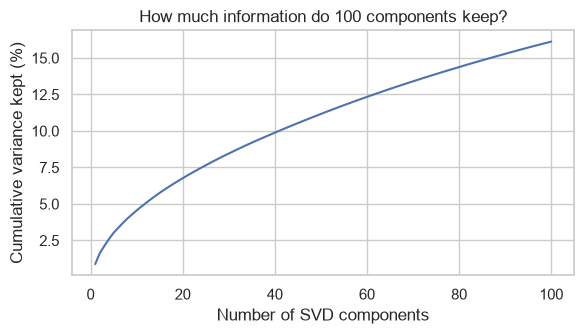

In [7]:
start = time.time()
svd = TruncatedSVD(n_components=100, n_iter=3, random_state=42)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_val_svd = svd.transform(X_val_tfidf)
print(f"Done in {time.time() - start:.0f} s | shape: {X_train_svd.shape}")

explained = np.cumsum(svd.explained_variance_ratio_)
print(f"Variance kept by 100 components: {explained[-1] * 100:.1f}%")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, 101), explained * 100)
plt.xlabel("Number of SVD components")
plt.ylabel("Cumulative variance kept (%)")
plt.title("How much information do 100 components keep?")
plt.tight_layout()
plt.savefig(ASSETS / "svd_explained_variance.png", dpi=150)
plt.show()

**Why 100?** It is a balance: more components keep more information but make KNN / trees slower. Text TF-IDF spreads information over many directions, so 100 components keep only a modest share of the variance - this is *normal for text*, and is also why the SVD-based models are expected to be weaker than the linear models on full TF-IDF (we check this in notebook 04).

## 7. Save everything for the next notebooks

In [8]:
sp.save_npz(PROC / "X_train_tfidf.npz", X_train_tfidf, compressed=False)
sp.save_npz(PROC / "X_val_tfidf.npz", X_val_tfidf, compressed=False)
np.save(PROC / "X_train_svd.npy", X_train_svd)
np.save(PROC / "X_val_svd.npy", X_val_svd)
y_train.to_csv(PROC / "y_train.csv", index=False)
y_val.to_csv(PROC / "y_val.csv", index=False)
X_train.to_frame("clean_text").join(y_train).to_csv(PROC / "train_clean.csv", index=False)
X_val.to_frame("clean_text").join(y_val).to_csv(PROC / "val_clean.csv", index=False)
joblib.dump(tfidf_union, MODELS / "tfidf_union_series.pkl")
joblib.dump(svd, MODELS / "svd.pkl")
print("Saved to", PROC.resolve())

Saved to C:\Users\abhij\Downloads\toxicity-moderation\data\processed


Next: `03_baseline_model.ipynb`.